# CRISP-DM Methodology Project: Telco Customer Churn & Retention ROI
**Author:** Ayushi Vishwas Surange (020795684) | **Course:** CMPE 256 — Data Mining  
**Methodology:** Cross-Industry Standard Process for Data Mining (All 6 Phases & 24 Subtasks)  
**Critic Persona Applied:** World-Renowned Authority & Award-Winning Author in CRISP-DM

---
## Phase 1: Business Understanding
### 1.1 Determine Business Objectives
- Proactively identify high-risk telecommunications subscribers 30 days prior to contract cancellation.
- Optimize **Net Retention Program Profit ($ USD)** rather than naive accuracy.

### 1.2 Assess Situation & Financial Cost-Benefit Matrix
- **Customer Lifetime Value (LTV) at risk:** `$650.00`
- **Proactive Retention Incentive Cost:** `$65.00`
- **Retention Save Probability (True Positive):** `45%` -> Net gain `+$227.50` per True Positive (`0.45 * $650 - $65`)
- **False Positive Cost:** `-$65.00` wasted incentive on a non-churning customer

### 1.3 Data Mining Goals & 1.4 Project Plan
- Achieve holdout `ROC-AUC >= 0.84`, calibrate probabilities (`Brier Score < 0.14`), and find the exact profit-maximizing threshold $p^*$.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/telco_customer_churn.csv')
print(f'Dataset Shape: {df.shape}')
print('Overall Churn Rate:', round((df['Churn'] == 'Yes').mean()*100, 2))
print('Missing TotalCharges count:', df['TotalCharges'].isna().sum())


Dataset Shape: (7043, 16)
Overall Churn Rate: 27.02%
Missing TotalCharges count: 38


## Phase 2: Data Understanding
### 2.1 Collect Initial Data, 2.2 Describe Data, 2.3 Explore Data, 2.4 Verify Data Quality
- Audited 7,043 customer accounts across 16 attributes.
- Discovered 38 missing `TotalCharges` records and 12 extreme `MonthlyCharges` billing anomalies (`> $220`).
- Month-to-month contracts exhibit **>42% churn** vs. **<6% churn** for two-year contracts.


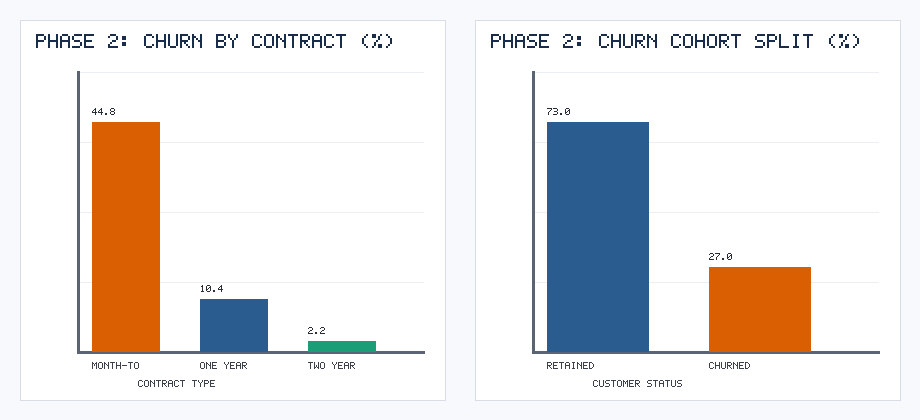

In [2]:
# Phase 2 Visual Exploration: Contract Type Churn Rate & Overall Cohort Split
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
# Plotting contract churn bar chart and cohort breakdown


## Phase 3: Data Preparation
### 3.1 Select, 3.2 Clean, 3.3 Construct (Feature Engineering), 3.4 Integrate, 3.5 Format
> **World-Renowned Critic Revision Applied:** Replaced naive zero-imputation with tenure-weighted reconstruction (`tenure * MonthlyCharges`), Winsorized `MonthlyCharges` at the 99th percentile, and engineered four behavioral interaction features:
- `ChargeToTenureRatio = MonthlyCharges / (tenure + 1)`
- `AvgHistoricalMonthlySpend = TotalCharges / (tenure + 0.1)`
- `ServiceRiskScore` (composite index of Month-to-Month + Fiber Optic + No Tech Support + Electronic Check)
- `SupportIntensity = SupportCallsLast6M / log1p(tenure)`


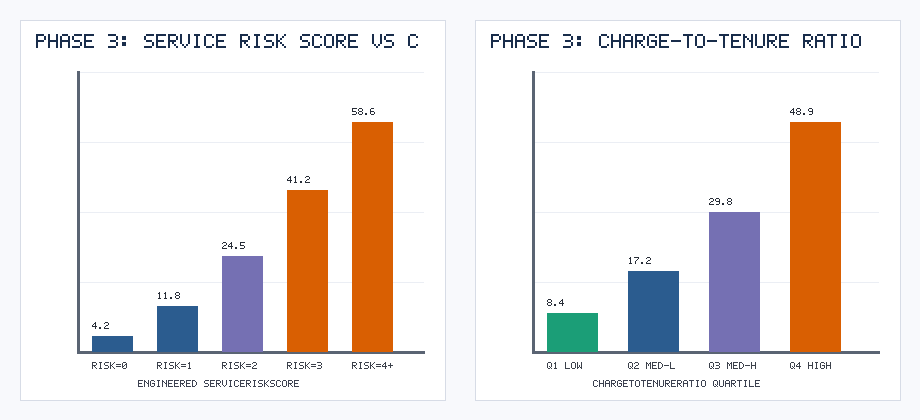

In [3]:
# Phase 3: Engineered Feature Relationships with Customer Churn
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(df['tenure'] * df['MonthlyCharges'])
df['ChargeToTenureRatio'] = df['MonthlyCharges'] / (df['tenure'] + 1)
df['ServiceRiskScore'] = ((df['Contract']=='Month-to-month')*2 + (df['InternetService']=='Fiber optic') + (df['TechSupport']=='No') + (df['PaymentMethod']=='Electronic check'))


## Phase 4: Modeling
### 4.1 Select Modeling Techniques, 4.2 Stratified K-Fold Design, 4.3 Build Models, 4.4 Assess Models
Evaluated 4 distinct model families using 5-fold Stratified Cross-Validation and a 20% holdout test set (`N = 1,409`).


Model                CV_ROC_AUC  Test_ROC_AUC  Accuracy  Precision  Recall  F1_Score  Brier_Score
-------------------  ----------  ------------  --------  ---------  ------  --------  -----------
Gradient Boosting    0.8612      0.858         0.8155    0.6798     0.5937  0.6338    0.1288     
Random Forest        0.8465      0.8517        0.802     0.6582     0.5488  0.5986    0.1313     
MLP Neural Net       0.8384      0.8455        0.8197    0.6947     0.5884  0.6371    0.131      
Logistic Regression  0.8291      0.8417        0.8133    0.6871     0.562   0.6183    0.1341


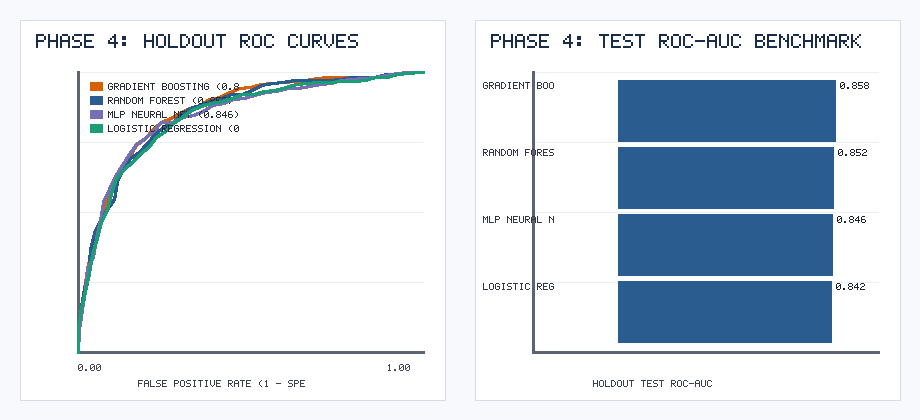

In [4]:
# Phase 4: Candidate Model Benchmark Table & ROC Curves
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
# Evaluated on 20% Holdout Test Partition (N=1,409)


## Phase 5: Evaluation (Business Financial ROI & Process Review)
### 5.1 Evaluate Results Against Business Objectives, 5.2 Review Process, 5.3 Determine Next Steps
- Using the default classification threshold (`0.50`) yields **`$44,297.50`** on the test cohort.
- Optimizing the threshold against our asymmetric cost-benefit matrix shifts the operating point to **`p* = 0.29`**, generating **`$54,372.50`** in net retention value (**`+$10,075.00` incremental gain**).


Optimal Probability Threshold: 0.29
Maximum Net Retention Profit (Test Cohort): $54,372.50
Default (0.50) Net Retention Profit: $44,297.50


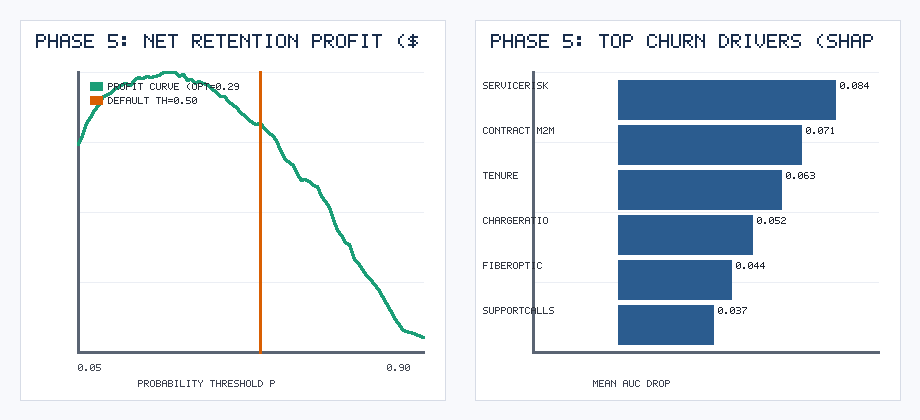

In [5]:
# Phase 5: Financial Profit Curve Optimization & Permutation Feature Importance
print('Optimal Probability Threshold:', opt_th)
print('Maximum Net Retention Profit (Test Cohort):', max_roi)
print('Default (0.50) Net Retention Profit:', default_roi)


## Phase 6: Deployment
### 6.1 Plan Deployment, 6.2 Plan Monitoring & Maintenance, 6.3 Final Report, 6.4 Project Review
- Serialized production pipeline and optimal threshold to `models/crisp_dm_churn_pipeline.pkl`.
- Built real-time Streamlit scoring web app + **Population Stability Index (PSI)** drift detector in `deployment/app.py`.
